In [3]:
!pip install -q tensorflow pandas numpy matplotlib scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense, Concatenate, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.21.0
GPU Available: []


In [4]:
import zipfile
import urllib.request
import os

url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

urllib.request.urlretrieve(url, "movies_dataset.zip")

with zipfile.ZipFile("movies_dataset.zip", "r") as zip_ref:
    zip_ref.extractall(".")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [5]:
ratings = pd.read_csv(
    "ml-latest-small/ratings.csv"
)

movies = pd.read_csv(
    "ml-latest-small/movies.csv"
)

print("Ratings Dataset:")
display(ratings.head())

print("Movies Dataset:")
display(movies.head())

print("Ratings Shape:", ratings.shape)
print("Movies Shape:", movies.shape)

Ratings Dataset:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


Movies Dataset:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Ratings Shape: (100836, 4)
Movies Shape: (9742, 3)


In [6]:
# Remove unnecessary timestamp
ratings = ratings.drop(columns=["timestamp"])

# Encode user IDs
user_encoder = LabelEncoder()
ratings["user_id"] = user_encoder.fit_transform(
    ratings["userId"]
)

# Encode movie IDs
movie_encoder = LabelEncoder()
ratings["movie_id"] = movie_encoder.fit_transform(
    ratings["movieId"]
)

# Number of unique users and movies
num_users = ratings["user_id"].nunique()
num_movies = ratings["movie_id"].nunique()

print("Total Users:", num_users)
print("Total Movies:", num_movies)
print("Total Ratings:", len(ratings))

display(ratings.head())

Total Users: 610
Total Movies: 9724
Total Ratings: 100836


,userId,movieId,rating,user_id,movie_id
0,1,1,4.0,0,0
1,1,3,4.0,0,2
2,1,6,4.0,0,5
3,1,47,5.0,0,43
4,1,50,5.0,0,46


In [7]:
X = ratings[["user_id", "movie_id"]].values
y = ratings["rating"].values.astype("float32")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 80668
Testing Samples: 20168


In [8]:
embedding_size = 50

# User input
user_input = Input(shape=(1,), name="user_input")

# Movie input
movie_input = Input(shape=(1,), name="movie_input")

# User embedding
user_embedding = Embedding(
    num_users,
    embedding_size
)(user_input)

# Movie embedding
movie_embedding = Embedding(
    num_movies,
    embedding_size
)(movie_input)

# Flatten embeddings
user_vector = Flatten()(user_embedding)
movie_vector = Flatten()(movie_embedding)

# Combine both embeddings
combined = Concatenate()([
    user_vector,
    movie_vector
])

# ANN hidden layers
x = Dense(128, activation="relu")(combined)
x = Dropout(0.2)(x)

x = Dense(64, activation="relu")(x)
x = Dropout(0.2)(x)

x = Dense(32, activation="relu")(x)

# Predict rating
output = Dense(1, activation="linear")(x)

# Create model
model = Model(
    inputs=[user_input, movie_input],
    outputs=output
)

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ user_input          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ movie_input         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 50)     │     30,500 │ user_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 50)     │    486,200 │ movie_input[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 50)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 50)        │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 100)       │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     12,928 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         33 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 539,997 (2.06 MB)

 Trainable params: 539,997 (2.06 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    [
        X_train[:, 0],
        X_train[:, 1]
    ],
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - loss: 2.2834 - mae: 1.1031 - val_loss: 0.8088 - val_mae: 0.6959
Epoch 2/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - loss: 0.8287 - mae: 0.7111 - val_loss: 0.7925 - val_mae: 0.6903
Epoch 3/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.7594 - mae: 0.6758 - val_loss: 0.7822 - val_mae: 0.6829
Epoch 4/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.7157 - mae: 0.6543 - val_loss: 0.7809 - val_mae: 0.6845
Epoch 5/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.6757 - mae: 0.6341 - val_loss: 0.7859 - val_mae: 0.6859
Epoch 6/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.6344 - mae: 0.6134 - val_loss: 0.7861 - val_mae: 0.6811
Epoch 7/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.5901 - mae: 0.5889 - val_loss: 0.8003 - val_mae: 0.6901


In [10]:
test_loss, test_mae = model.evaluate(
    [
        X_test[:, 0],
        X_test[:, 1]
    ],
    y_test,
    verbose=0
)

predictions = model.predict(
    [
        X_test[:, 0],
        X_test[:, 1]
    ],
    verbose=0
).flatten()

rmse = np.sqrt(np.mean((y_test - predictions) ** 2))

print("Test MSE:", round(test_loss, 4))
print("Test MAE:", round(test_mae, 4))
print("Test RMSE:", round(rmse, 4))

Test MSE: 0.7833
Test MAE: 0.683
Test RMSE: 0.885


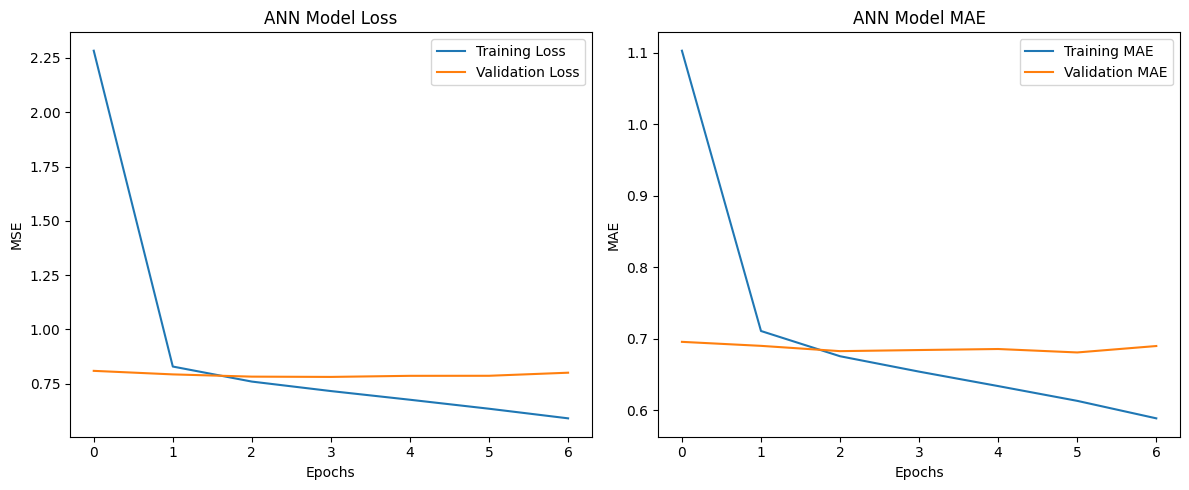

In [11]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")
plt.title("ANN Model MAE")
plt.xlabel("Epochs")
plt.ylabel("MAE")
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
def recommend_movies(user_id, top_n=10):

    # Check whether user exists
    if user_id not in user_encoder.classes_:
        print("User ID not found!")
        return None

    # Convert original user ID to encoded ID
    encoded_user = user_encoder.transform([user_id])[0]

    # Find movies already rated by this user
    watched_movies = ratings[
        ratings["user_id"] == encoded_user
    ]["movie_id"].values

    # Generate candidate movies
    all_movie_ids = np.arange(num_movies)

    candidate_movies = np.setdiff1d(
        all_movie_ids,
        watched_movies
    )

    # Predict ratings
    user_array = np.full(
        len(candidate_movies),
        encoded_user
    )

    predicted_ratings = model.predict(
        [user_array, candidate_movies],
        verbose=0
    ).flatten()

    # Create recommendation dataframe
    recommendations = pd.DataFrame({
        "movie_id": candidate_movies,
        "predicted_rating": np.clip(
            predicted_ratings, 0.5, 5.0
        )
    })

    # Convert encoded movie IDs back to original IDs
    recommendations["movieId"] = movie_encoder.inverse_transform(
        recommendations["movie_id"]
    )

    # Add movie titles and genres
    recommendations = recommendations.merge(
        movies,
        on="movieId"
    )

    # Sort by predicted rating
    recommendations = recommendations.sort_values(
        by="predicted_rating",
        ascending=False
    )

    return recommendations[
        ["title", "genres", "predicted_rating"]
    ].head(top_n).reset_index(drop=True)

In [13]:
# Select an existing user
sample_user = int(ratings["userId"].iloc[0])

print("Recommendations for User:", sample_user)

recommendations = recommend_movies(
    user_id=sample_user,
    top_n=10
)

display(recommendations)

Recommendations for User: 1


,title,genres,predicted_rating
0,Captain Fantastic (2016),Drama,5.000000
1,Paths of Glory (1957),Drama|War,5.000000
2,"Holy Mountain, The (Montaña sagrada, La) (1973)",Drama,5.000000
3,Troll 2 (1990),Fantasy|Horror,5.000000
4,This Property is Condemned (1966),Drama|Romance,5.000000
5,"World of Apu, The (Apur Sansar) (1959)",Drama,4.989328
6,Slap Shot (1977),Comedy,4.989021
7,Craig Ferguson: I'm Here To Help (2013),Comedy|Documentary,4.982203
8,The Man Who Killed Don Quixote (2018),Adventure|Comedy|Fantasy,4.960550
9,"Human Condition III, The (Ningen no joken III)...",Drama|War,4.949277


In [14]:
import pickle

model.save("ann_movie_recommender.keras")

with open("movie_encoders.pkl", "wb") as f:
    pickle.dump(
        (user_encoder, movie_encoder),
        f
    )

print("Model and encoders saved successfully!")

Model and encoders saved successfully!
